# CosmoFit — CPL vs ΛCDM with the full CMB: Planck + DESI DR2 + SN Ia + chronometers

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/salihyesil59/CosmoFit/blob/main/examples/05-case-studies/cpl_vs_lcdm_full_cmb.ipynb)

Two models are fit to the same data:

- **ΛCDM:** the six standard parameters.
- **CPL:** the same six, plus $w(a) = w_0 + w_a(1-a)$, i.e. $w(z) = w_0 + w_a\,z/(1+z)$.

The question: how far from $w_0 = -1,\ w_a = 0$ does the data want to go, and are the two extra parameters worth it?

How strong DESI DR2's dynamical dark energy signal is depends on which supernova sample goes with it. So the analysis is repeated with three: **Pantheon+**, **Union3** and **DES-SN5YR**. That makes six chains (2 models × 3 SN sets).

Unlike the other CPL case studies, the CMB here is not compressed into distance priors. The full Planck TT/TE/EE, low-ℓ EE and lensing likelihoods are used, so $\omega_b$, $\omega_c$, $n_s$, $A_s$ and $\tau$ are all sampled. That is affordable because of the `fastcmb` theory: CAMB with an emulator in front of it that learns as the chain runs. It predicts most points in milliseconds and runs CAMB where it is unsure. Section 9 checks it against CAMB.

**Contents**

1. Setup, checks and running
2. Convergence
3. Posteriors: parameter table, triangle plots
4. The $w_0$–$w_a$ plane and CPL diagnostics ($w=-1$ crossing, regions, distance from ΛCDM)
5. $w(z)$ and $\rho_\mathrm{DE}(z)$
6. Expansion history: $q(z)$, $H(z)$ and chronometers, DESI BAO distances, SN Hubble residuals
7. $H_0$, $\Omega_m$, $S_8$, $r_d$ across the six runs
8. Model comparison: Δχ², likelihood-ratio test, AIC, BIC, and which data say what
9. How accurate the emulator is
10. Conclusions

## Data

| Likelihood | What it measures | N | Note |
|---|---|---|---|
| `cmb.planck_lite` | Planck 2018 TT/TE/EE, ℓ = 30–2508 (+ 2 low-ℓ TT bins) | 615 | calibration `A_planck` |
| `cmb.planck_lowe` | low-ℓ EE, ℓ = 2–29 | 28 | constrains τ |
| `cmb.planck_lensing` | lensing potential $C_L^{\phi\phi}$ | 9 | |
| `bao.desi` (`desi2025`) | DESI DR2 BAO: $D_M/r_d$, $D_H/r_d$, $D_V/r_d$ | 13 | $r_d$ computed by the model |
| `sn.pantheonplus` | Pantheon+ SN Ia, $z > 0.01$ | 1590 | no SH0ES; $M_B$ marginalized |
| `sn.union3` | Union3 (UNITY1.5), binned | 22 | offset marginalized |
| `sn.des_sn5yr` | DES-SN5YR, Dovekie recalibration | 1820 | offset marginalized |
| `cc.chronometers` (`favale2023`) | $H(z)$ from cosmic chronometers | 32 | Moresco et al. systematic covariance |

Each run has one SN set. The three share part of their supernovae, so they are never combined.

For DES-SN5YR, CosmoFit loads the **DES-Dovekie** release (Popovic et al. 2025), whose photometric calibration was redone. It is not the original release (DES Collaboration 2024) that the DESI DR2 paper used. The recalibration weakens DES's $w_0w_a$ signal, so the DES result here sits closer to ΛCDM than the DESI DR2 paper's "DESY5" one.

## Parameters

| | Parameter | Prior |
|---|---|---|
| ΛCDM and CPL | $\omega_b,\ \omega_c,\ H_0,\ \tau,\ \ln(10^{10}A_s),\ n_s$ | wide, flat |
| CPL only | $w_0 \in [-3, 1]$, $w_a \in [-3, 2]$ | flat (as in DESI DR2) |
| nuisance | `A_planck` | Gaussian: $1 \pm 0.0025$ |
| fixed | $\sum m_\nu = 0.06$ eV | |

Planck's own analysis samples $100\,\theta_\mathrm{MC}$ rather than $H_0$. Here $H_0$ is sampled and $\theta_*$ is derived. The posterior is the same; only the coordinate it is sampled in differs.

Convergence criterion: $R-1 < 0.01$ (4 chains, Gelman–Rubin).

The inputs are the six YAML files in [`examples/yaml/cpl_vs_lcdm/`](../yaml/cpl_vs_lcdm/), one per model and SN set.

## 1. Setup

On Colab this clones the repository (for the YAML files) and installs CosmoFit with CAMB, `fastcmb` and `getdist`. Locally, it only moves to the repository root, which the YAML files' paths are relative to.

The chains are not part of the repository: they take about an hour each (section 1.2). This notebook reads them from `chains/cpl_vs_lcdm/` once they exist.

In [1]:
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    !git clone -q --depth 1 -b dev https://github.com/salihyesil59/CosmoFit
    !pip install -q "./CosmoFit[cmb]" getdist "fastcmb @ git+https://github.com/salihyesil59/fastcmb"
    os.chdir("CosmoFit")
else:
    print('Not running in Colab -- assuming CosmoFit is already installed '
          '(pip install "cosmofit[fast]" getdist).')

# The YAML files' paths are relative to the repository root.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "examples" / "yaml" / "cpl_vs_lcdm").is_dir())
os.chdir(ROOT)
print("working in", ROOT)

Not running in Colab -- assuming CosmoFit is already installed (pip install "cosmofit[fast]" getdist).
working in C:\Users\salih\Github\physics\CosmoFit


In [2]:
import glob
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from getdist import loadMCSamples, plots

from cosmofit.core import load_info, get_model, run
from cosmofit.stats import model_comparison, cpl_diagnostics
from cosmofit.data.loaders import bao, cc, sn

%matplotlib inline
warnings.simplefilter("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

YAML = ROOT / "examples" / "yaml" / "cpl_vs_lcdm"
MODELS = ("LCDM", "CPL")
SN_SETS = {"Pantheon+": "pantheonplus", "Union3": "union3", "DES-SN5YR": "des_sn5yr"}
RUNS = [(m, s) for s in SN_SETS for m in MODELS]

def config(model, sn_set):
    return YAML / f"{model.lower()}_{SN_SETS[sn_set]}.yaml"

def chain_prefix(model, sn_set):
    return ROOT / load_info(str(config(model, sn_set)))["output"]

COLOR = {"Pantheon+": "#1f77b4", "Union3": "#d62728", "DES-SN5YR": "#2ca02c", "LCDM": "0.45"}
LINE = {"LCDM": "--", "CPL": "-"}

FIGURE_DIR = ROOT / "examples" / "05-case-studies" / "cpl_vs_lcdm_full_cmb_figures"
FIGURE_DIR.mkdir(exist_ok=True)

def savefig(fig, name):
    # saved as cpl_vs_lcdm_full_cmb_figures/<name>.svg
    for ax in fig.get_axes():
        for artist in [*ax.get_lines(), *ax.collections]:
            try:
                n_points = len(artist.get_xdata())
            except AttributeError:
                offsets = artist.get_offsets()
                n_points = 0 if offsets is None else len(offsets)
            if n_points > 2000:
                artist.set_rasterized(True)
    path = FIGURE_DIR / f"{name}.svg"
    fig.savefig(path, format="svg", bbox_inches="tight", dpi=150)
    print(f"saved {path.name} ({path.stat().st_size / 1e6:.2f} MB)")

### 1.1 Do the inputs build?

Before any chain, each model is built and evaluated once at its starting point. Each χ² should be roughly the number of data points (except Planck lowE, a non-Gaussian likelihood whose $-2\ln L$ carries an offset). This cell also collects the data counts `n_data` that AIC and BIC need.

In [3]:
def reference_point(info):
    return {n: s["ref"]["loc"] for n, s in info["params"].items() if isinstance(s, dict) and "ref" in s}

N_DATA = {}
for model, sn_set in RUNS:
    info = load_info(str(config(model, sn_set)))
    info.pop("sampler"); info.pop("output")
    m = get_model(info)
    counts = {c.name: c.legacy.n_data for c in m.components if hasattr(c, "legacy")}
    N_DATA[sn_set] = counts
    if sn_set != "Pantheon+":
        continue
    point = m.logposterior(reference_point(info))
    print(f"{model}: sampled {m.parameters.sampled}")
    for lk, logl in point.loglikes.items():
        print(f"   {lk:22s} chi2 = {-2 * logl:8.1f}   N = {counts[lk]}")

for sn_set, counts in N_DATA.items():
    print(f"{sn_set:10s} total N = {sum(counts.values())}")

LCDM: sampled ['ln1e10As', 'n_s', 'tau_reio', 'A_planck', 'omega_b', 'omega_cdm', 'H0']
   cmb.planck_lite        chi2 =    598.4   N = 615
   cmb.planck_lowe        chi2 =    396.2   N = 28
   cmb.planck_lensing     chi2 =      8.5   N = 9
   bao.desi               chi2 =     25.5   N = 13
   sn.pantheonplus        chi2 =   1404.1   N = 1590
   cc.chronometers        chi2 =     13.5   N = 32


CPL: sampled ['ln1e10As', 'n_s', 'tau_reio', 'A_planck', 'omega_b', 'omega_cdm', 'H0', 'w0', 'wa']
   cmb.planck_lite        chi2 =    617.6   N = 615
   cmb.planck_lowe        chi2 =    396.2   N = 28
   cmb.planck_lensing     chi2 =      8.6   N = 9
   bao.desi               chi2 =      8.0   N = 13
   sn.pantheonplus        chi2 =   1405.5   N = 1590
   cc.chronometers        chi2 =     13.0   N = 32


Pantheon+  total N = 2287
Union3     total N = 719
DES-SN5YR  total N = 2517


### 1.2 Running the chains

Each run is its own set of processes. It is best started from a terminal, at the repository root:

```bash
cosmofit run examples/yaml/cpl_vs_lcdm/lcdm_pantheonplus.yaml
cosmofit run examples/yaml/cpl_vs_lcdm/cpl_pantheonplus.yaml
# then the Union3 and DES-SN5YR ones, which start from the covmats these two learn
cosmofit run examples/yaml/cpl_vs_lcdm/lcdm_union3.yaml      # and cpl_union3, lcdm_des_sn5yr, cpl_des_sn5yr
```

- Each run uses 4 chains in 4 processes. Several can run at the same time.
- `--resume` continues an interrupted run; `--force` starts over.
- The CAMB points the emulator learns are kept in `chains/cpl_vs_lcdm/emu_*/`. A model run again with another SN set reuses them, which is why the Union3 and DES-SN5YR runs need far fewer CAMB calls.
- Here the Pantheon+ runs took 31 min (ΛCDM) and 52 min (CPL) side by side. The other four took 15–25 min each. `max_time: 21600` is a 6-hour safety stop.

The best-fit points (section 8) come from a minimization started at each chain's best point:

```bash
python examples/yaml/cpl_vs_lcdm/bestfit.py lcdm_pantheonplus cpl_pantheonplus lcdm_union3 cpl_union3 lcdm_des_sn5yr cpl_des_sn5yr
```

To run everything from this notebook instead, set `RUN = True`. The cell blocks until all chains are done.

In [4]:
RUN = False

if RUN:
    for model, sn_set in RUNS:
        run(str(config(model, sn_set)))

## 2. Convergence

The `.progress` file records the number of steps, the acceptance rate and $R-1$ at each check. Dashed lines are ΛCDM, solid lines CPL.

saved convergence.svg (0.06 MB)


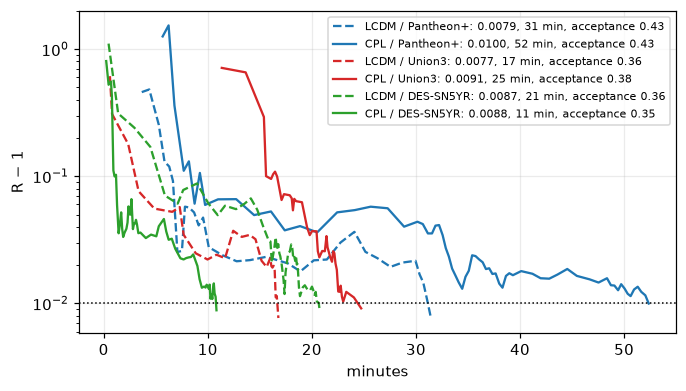

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for model, sn_set in RUNS:
    progress = Path(f"{chain_prefix(model, sn_set)}.progress")
    if not progress.exists():
        print(f"{model} / {sn_set}: no output yet")
        continue
    steps, acceptance, Rminus1, seconds = np.loadtxt(progress, ndmin=2).T
    ax.semilogy(seconds / 60, Rminus1, LINE[model], color=COLOR[sn_set],
                label=f"{model} / {sn_set}: {Rminus1[-1]:.4f}, {seconds[-1] / 60:.0f} min, acceptance {acceptance[-1]:.2f}")
ax.axhline(0.01, color="k", ls=":", lw=1)
ax.set(xlabel="minutes", ylabel="R − 1")
ax.legend(fontsize=7.5)
savefig(fig, "convergence")

## 3. Posteriors

The first 30% of each chain is dropped as burn-in.

In [6]:
samples = {}
for model, sn_set in RUNS:
    s = loadMCSamples(str(chain_prefix(model, sn_set)), settings={"ignore_rows": 0.3})
    s.label = f"{model} / {sn_set}"
    samples[model, sn_set] = s

shown = ["omega_b", "omega_cdm", "H0", "tau_reio", "ln1e10As", "n_s",
         "Omega_m", "sigma8", "S8", "rdrag", "w0", "wa"]

def mean_sd(s, p):
    if s.paramNames.parWithName(p) is None:
        return "—"
    m, sd = s.mean(p), s.std(p)
    digits = max(0, 1 - int(np.floor(np.log10(sd))))
    return f"{m:.{digits}f} ± {sd:.{digits}f}"

pd.DataFrame({f"{m} / {s_}": {p: mean_sd(samples[m, s_], p) for p in shown} for m, s_ in RUNS}).T

C:\Users\salih\Github\physics\CosmoFit\chains\cpl_vs_lcdm\lcdm_pantheonplus.1.txt


C:\Users\salih\Github\physics\CosmoFit\chains\cpl_vs_lcdm\lcdm_pantheonplus.2.txt


C:\Users\salih\Github\physics\CosmoFit\chains\cpl_vs_lcdm\lcdm_pantheonplus.3.txt


C:\Users\salih\Github\physics\CosmoFit\chains\cpl_vs_lcdm\lcdm_pantheonplus.4.txt


Removed 0.3 as burn in


...

Removed 0.3 as burn in


C:\Users\salih\Github\physics\CosmoFit\chains\cpl_vs_lcdm\lcdm_union3.1.txt
C:\Users\salih\Github\physics\CosmoFit\chains\cpl_vs_lcdm\lcdm_union3.2.txt
C:\Users\salih\Github\physics\CosmoFit\chains\cpl_vs_lcdm\lcdm_union3.3.txt
C:\Users\salih\Github\physics\CosmoFit\chains\cpl_vs_lcdm\lcdm_union3.4.txt
Removed 0.3 as burn in
C:\Users\salih\Github\physics\CosmoFit\chains\cpl_vs_lcdm\cpl_union3.1.txt
C:\Users\salih\Github\physics\CosmoFit\chains\cpl_vs_lcdm\cpl_union3.2.txt
C:\Users\salih\Github\physics\CosmoFit\chains\cpl_vs_lcdm\cpl_union3.3.txt


C:\Users\salih\Github\physics\CosmoFit\chains\cpl_vs_lcdm\cpl_union3.4.txt
Removed 0.3 as burn in
C:\Users\salih\Github\physics\CosmoFit\chains\cpl_vs_lcdm\lcdm_des_sn5yr.1.txt
C:\Users\salih\Github\physics\CosmoFit\chains\cpl_vs_lcdm\lcdm_des_sn5yr.2.txt
C:\Users\salih\Github\physics\CosmoFit\chains\cpl_vs_lcdm\lcdm_des_sn5yr.3.txt
C:\Users\salih\Github\physics\CosmoFit\chains\cpl_vs_lcdm\lcdm_des_sn5yr.4.txt


Removed 0.3 as burn in
C:\Users\salih\Github\physics\CosmoFit\chains\cpl_vs_lcdm\cpl_des_sn5yr.1.txt
C:\Users\salih\Github\physics\CosmoFit\chains\cpl_vs_lcdm\cpl_des_sn5yr.2.txt
C:\Users\salih\Github\physics\CosmoFit\chains\cpl_vs_lcdm\cpl_des_sn5yr.3.txt
C:\Users\salih\Github\physics\CosmoFit\chains\cpl_vs_lcdm\cpl_des_sn5yr.4.txt
Removed 0.3 as burn in


,omega_b,omega_cdm,H0,tau_reio,ln1e10As,n_s,Omega_m,sigma8,S8,rdrag,w0,wa
LCDM / Pantheon+,0.02253 ± 0.00012,0.11777 ± 0.00065,68.35 ± 0.29,0.0598 ± 0.0073,3.051 ± 0.014,0.9708 ± 0.0033,0.3017 ± 0.0037,0.8074 ± 0.0059,0.8096 ± 0.0083,147.51 ± 0.19,—,—
CPL / Pantheon+,0.02245 ± 0.00014,0.11896 ± 0.00089,67.67 ± 0.60,0.0555 ± 0.0073,3.044 ± 0.014,0.9678 ± 0.0036,0.3103 ± 0.0057,0.8102 ± 0.0092,0.8239 ± 0.0095,147.29 ± 0.22,-0.843 ± 0.054,-0.59 ± 0.20
LCDM / Union3,0.02254 ± 0.00013,0.11776 ± 0.00065,68.35 ± 0.30,0.0599 ± 0.0076,3.051 ± 0.015,0.9709 ± 0.0034,0.3017 ± 0.0038,0.8074 ± 0.0060,0.8097 ± 0.0083,147.51 ± 0.19,—,—
CPL / Union3,0.02243 ± 0.00013,0.11932 ± 0.00090,66.11 ± 0.86,0.0541 ± 0.0072,3.042 ± 0.014,0.9670 ± 0.0036,0.3259 ± 0.0089,0.799 ± 0.010,0.833 ± 0.010,147.22 ± 0.22,-0.677 ± 0.090,-1.04 ± 0.30
LCDM / DES-SN5YR,0.02252 ± 0.00012,0.11785 ± 0.00063,68.31 ± 0.29,0.0596 ± 0.0073,3.050 ± 0.014,0.9706 ± 0.0032,0.3023 ± 0.0036,0.8076 ± 0.0058,0.8106 ± 0.0081,147.50 ± 0.19,—,—
CPL / DES-SN5YR,0.02243 ± 0.00013,0.11914 ± 0.00088,67.47 ± 0.56,0.0546 ± 0.0072,3.042 ± 0.014,0.9674 ± 0.0036,0.3125 ± 0.0055,0.8095 ± 0.0088,0.8262 ± 0.0095,147.26 ± 0.22,-0.809 ± 0.056,-0.70 ± 0.22


ΛCDM against CPL on the shared parameters (Pantheon+). Freeing $w_0, w_a$ widens and shifts $H_0$ and $\Omega_m$: late-time distances can now be balanced by the trio $H_0$–$\Omega_m$–$w$. The early-universe parameters ($\omega_c$, $n_s$, $r_d$) barely move, because the CMB fixes them on its own.

saved triangle_lcdm_vs_cpl.svg (1.64 MB)


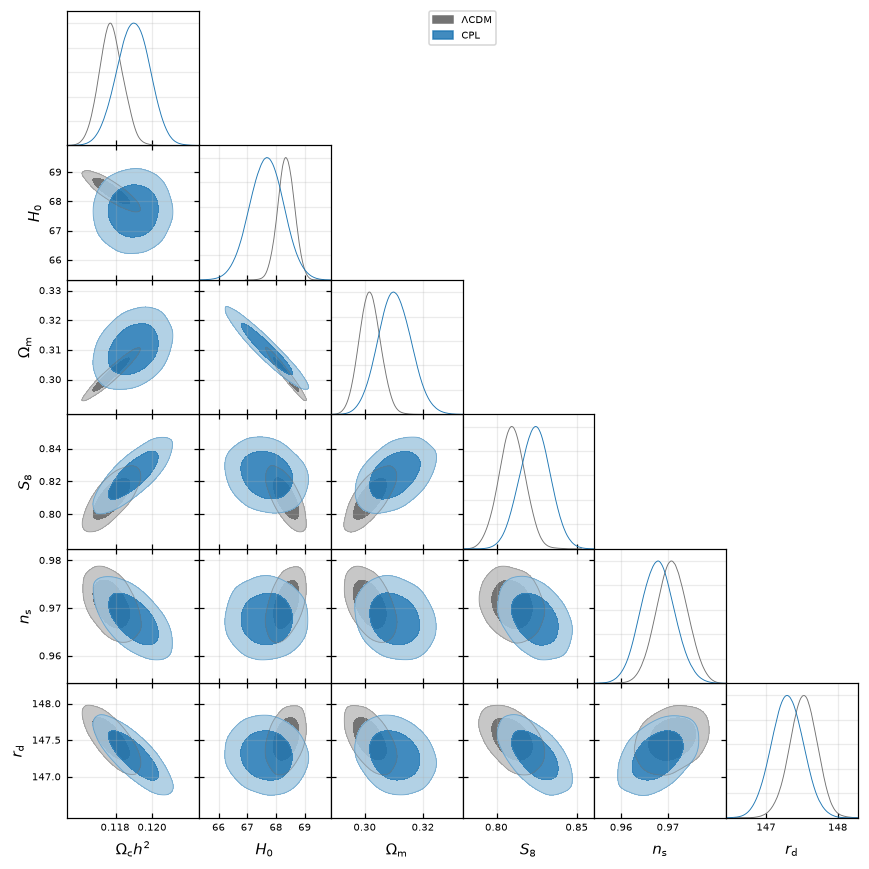

In [7]:
g = plots.get_subplot_plotter(width_inch=8)
g.settings.legend_fontsize = 11
g.triangle_plot([samples["LCDM", "Pantheon+"], samples["CPL", "Pantheon+"]],
                ["omega_cdm", "H0", "Omega_m", "S8", "n_s", "rdrag"],
                filled=True, legend_labels=["ΛCDM", "CPL"],
                contour_colors=[COLOR["LCDM"], COLOR["Pantheon+"]])
savefig(g.fig, "triangle_lcdm_vs_cpl")

CPL with the three SN sets. The differences along $w_0$–$w_a$ carry $H_0$ and $\Omega_m$ with them: the supernovae mainly measure $\Omega_m$ and the shape of the low-$z$ expansion.

saved triangle_cpl_sn_sets.svg (1.76 MB)


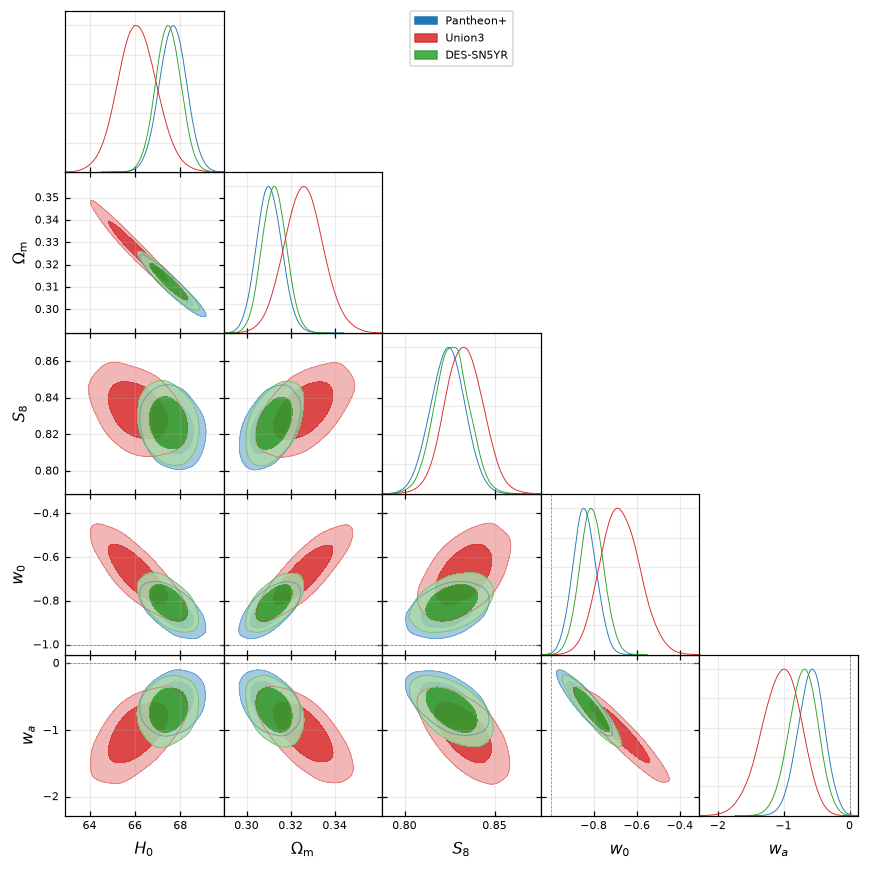

In [8]:
cpl = [samples["CPL", s_] for s_ in SN_SETS]
g = plots.get_subplot_plotter(width_inch=8)
g.settings.legend_fontsize = 11
g.triangle_plot(cpl, ["H0", "Omega_m", "S8", "w0", "wa"], filled=True,
                legend_labels=list(SN_SETS), contour_colors=[COLOR[s_] for s_ in SN_SETS],
                markers={"w0": -1, "wa": 0})
savefig(g.fig, "triangle_cpl_sn_sets")

## 4. The $w_0$–$w_a$ plane and CPL diagnostics

The star is ΛCDM. The labels on the plot read forward in time, from the past to today. The two dashed lines split the plane into four regions:

- $w_0 = -1$: the boundary between phantom ($w<-1$) and quintessence ($w>-1$) today.
- $w_0 + w_a = -1$: the same boundary for $w(z\to\infty)$, at early times.

A point on different sides of the two lines means $w(z)$ crosses $-1$ at some redshift. DESI points to the region that was phantom in the past and is quintessence today ($w_0 > -1$, $w_0 + w_a < -1$).

saved w0_wa.svg (0.27 MB)


Pantheon+  w_0 = -0.843\pm 0.054    w_a = -0.59\pm 0.20
Union3     w_0 = -0.677\pm 0.090    w_a = -1.04^{+0.32}_{-0.28}


DES-SN5YR  w_0 = -0.809\pm 0.056    w_a = -0.70\pm 0.22


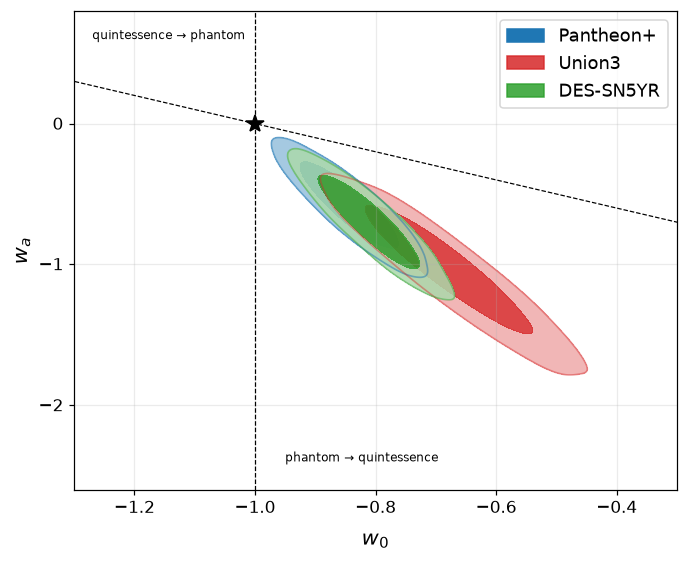

In [9]:
g = plots.get_single_plotter(width_inch=6.5, ratio=0.8)
g.plot_2d(cpl, "w0", "wa", filled=True, colors=[COLOR[s_] for s_ in SN_SETS])
ax = g.subplots[0, 0]
w0_line = np.linspace(-1.6, 0.0, 2)
ax.plot(w0_line, -1 - w0_line, "k--", lw=0.8)
ax.axvline(-1, color="k", ls="--", lw=0.8)
ax.plot(-1, 0, "k*", ms=12, zorder=10)
ax.set(xlim=(-1.3, -0.3), ylim=(-2.6, 0.8))
ax.text(-0.95, -2.4, "phantom → quintessence", fontsize=8)
ax.text(-1.27, 0.6, "quintessence → phantom", fontsize=8)
g.add_legend(list(SN_SETS), legend_loc="upper right")
savefig(g.fig, "w0_wa")
for s_ in SN_SETS:
    print(f"{s_:10s}", samples["CPL", s_].getInlineLatex("w0", limit=1), "  ",
          samples["CPL", s_].getInlineLatex("wa", limit=1))

**Diagnostics** (`cosmofit.stats.cpl_diagnostics`), over the posterior samples:

- **Distance from ΛCDM:** the Mahalanobis distance of $(-1, 0)$ from the $(w_0, w_a)$ posterior's mean and covariance, converted to σ in two dimensions. For a Gaussian posterior it should be close to what a profile likelihood gives.
- **Mass excluding ΛCDM:** the posterior mass at higher density than at the ΛCDM point. This does not assume a Gaussian posterior.
- **$w=-1$ crossing:** $z_\times = -(1+w_0)/(1+w_0+w_a)$. Reported as the fraction of samples that cross in $[0, 2.5]$, and their median $z_\times$.
- **Regions:** which region the samples fall in. `quintom-b` is quintessence today ($w_0>-1$) and phantom in the past ($w_0+w_a<-1$), where DESI points. The crossing direction is given in redshift: "quintessence → phantom with increasing z" is a crossing from phantom to quintessence in time.

In [10]:
rng = np.random.default_rng(1)

def draws(s, params, n=40_000):
    # equally weighted samples from a weighted chain
    w = s.weights / s.weights.sum()
    rows = rng.choice(len(w), n, p=w)
    return {p: s.samples[rows, s.index[p]] for p in params}

def lcdm_excluded(s):
    # posterior mass at higher 2D density than at the LCDM point
    density = s.get2DDensity("w0", "wa")
    at_lcdm = density.Prob(-1.0, 0.0)
    levels = density.P.ravel()
    return float(levels[levels > at_lcdm].sum() / levels.sum())

diag = {}
for s_ in SN_SETS:
    d = draws(samples["CPL", s_], ["w0", "wa"])
    maha = cpl_diagnostics.mahalanobis_from_lcdm(d["w0"], d["wa"])
    z_cross, frac = cpl_diagnostics.crossing_redshift(d["w0"], d["wa"])
    direction = cpl_diagnostics.crossing_direction(d["w0"], d["wa"])
    regions = cpl_diagnostics.region_fractions(d["w0"], d["wa"])
    excluded = lcdm_excluded(samples["CPL", s_])
    diag[s_] = {
        "distance from ΛCDM (Mahalanobis)": f"{maha['sigma']:.2f} σ",
        # with 40 000 samples the density's tail is not reliable beyond 99.9%
        "mass excluding ΛCDM": (f"{100 * excluded:.1f}% ({stats.norm.isf((1 - excluded) / 2):.1f} σ)"
                                if excluded < 0.999 else "> 99.9% (> 3.3 σ)"),
        "samples crossing w = −1": f"{100 * frac:.0f}%",
        "median z_×": f"{np.median(z_cross):.2f}" if len(z_cross) else "—",
        "with increasing z: quintessence → phantom": f"{100 * direction['quintessence_to_phantom']:.0f}%",
        "with increasing z: phantom → quintessence": f"{100 * direction['phantom_to_quintessence']:.0f}%",
        **{f"region: {k}": f"{100 * v:.0f}%" for k, v in regions.items()},
    }
pd.DataFrame(diag)

,Pantheon+,Union3,DES-SN5YR
distance from ΛCDM (Mahalanobis),2.54 σ,3.14 σ,3.02 σ
mass excluding ΛCDM,99.4% (2.7 σ),> 99.9% (> 3.3 σ),99.9% (3.3 σ)
samples crossing w = −1,100%,100%,100%
median z_×,0.37,0.45,0.37
with increasing z: quintessence → phantom,100%,100%,100%
with increasing z: phantom → quintessence,0%,0%,0%
region: phantom,0%,0%,0%
region: quintessence,0%,0%,0%
region: quintom-a,0%,0%,0%
region: quintom-b,100%,100%,100%


## 5. $w(z)$ and the dark energy density

Left: the 68% and 95% bands of $w(z)$. Right: the dark energy density relative to today's,

$$\frac{\rho_\mathrm{DE}(z)}{\rho_\mathrm{DE,0}} = (1+z)^{3(1+w_0+w_a)}\, \exp\!\left(-\frac{3 w_a z}{1+z}\right).$$

Both are constant in ΛCDM. The CPL preference is for a density that peaks near $z \approx 0.5$ and falls towards today. The CPL form fixes the curvature of $w(z)$, so the band at high $z$, where the data are weak, is largely set by the parametrization.

saved w_of_z.svg (0.19 MB)


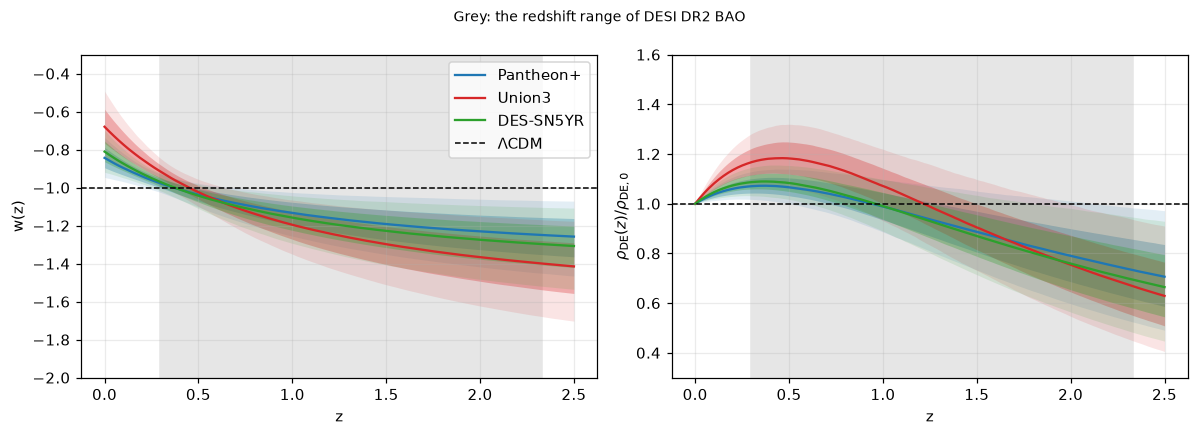

In [11]:
z = np.linspace(0, 2.5, 200)

def rho_de(w0, wa, z):
    return (1 + z) ** (3 * (1 + w0[:, None] + wa[:, None])) * np.exp(-3 * wa[:, None] * z / (1 + z))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
for s_ in SN_SETS:
    d = draws(samples["CPL", s_], ["w0", "wa"], 20_000)
    bands = cpl_diagnostics.wz_posterior_bands(d["w0"], d["wa"], z)
    a1.fill_between(z, bands[2.5], bands[97.5], color=COLOR[s_], alpha=0.12, lw=0)
    a1.fill_between(z, bands[16], bands[84], color=COLOR[s_], alpha=0.3, lw=0)
    a1.plot(z, bands[50], color=COLOR[s_], label=s_)
    r = np.percentile(rho_de(d["w0"], d["wa"], z), [2.5, 16, 50, 84, 97.5], axis=0)
    a2.fill_between(z, r[0], r[4], color=COLOR[s_], alpha=0.12, lw=0)
    a2.fill_between(z, r[1], r[3], color=COLOR[s_], alpha=0.3, lw=0)
    a2.plot(z, r[2], color=COLOR[s_])
for a in (a1, a2):
    a.axhline(-1 if a is a1 else 1, color="k", ls="--", lw=1, label="ΛCDM" if a is a1 else None)
    a.axvspan(0.295, 2.33, color="0.9", zorder=-1)      # DESI DR2 BAO's range
    a.set_xlabel("z")
a1.set(ylabel="w(z)", ylim=(-2.0, -0.3))
a2.set(ylabel=r"$\rho_\mathrm{DE}(z)/\rho_\mathrm{DE,0}$", ylim=(0.3, 1.6))
a1.legend()
fig.suptitle("Grey: the redshift range of DESI DR2 BAO", fontsize=9)
fig.tight_layout()
savefig(fig, "w_of_z")

## 6. Expansion history

The quantities in this section ($H(z)$, distances, $q(z)$) are computed from posterior samples. A light model is built for this: no CMB, only the background and $r_d$, at a few milliseconds per point. Each run contributes 400 samples and its best-fit point.

The best-fit points are read from the `*.bestfit.json` files that `bestfit.py` writes. Where a file is missing, the chain's lowest-χ² point stands in.

In [12]:
def background_model(model):
    info = load_info(str(config(model, "Pantheon+")))
    for key in ("sampler", "output"):
        info.pop(key)
    info["theory"].pop("fastcmb")
    info["likelihood"] = {"cc.chronometers": {"version": "favale2023"}}   # any cheap likelihood will do
    keep = {"omega_b", "omega_cdm", "H0", "m_nu", "w0", "wa", "Omega_m", "rdrag"}
    info["params"] = {k: v for k, v in info["params"].items() if k in keep}
    m = get_model(info)
    return m, next(c for c in m.components if c.name == "background")

BG = {model: background_model(model) for model in MODELS}

def best_point(model, sn_set):
    path = Path(f"{chain_prefix(model, sn_set)}.bestfit.json")
    s = samples[model, sn_set]
    parts = {p.name[6:]: s.samples[:, s.index[p.name]] for p in s.paramNames.names if p.name.startswith("chi2__")}
    i = int(np.argmin(sum(parts.values())))
    best = {"point": {p.name: float(s.samples[i, s.index[p.name]]) for p in s.paramNames.names},
            "parts": {k: float(v[i]) for k, v in parts.items()}}
    best["chi2"] = best["chi2_chain"] = sum(best["parts"].values())
    if path.exists():
        d = json.loads(path.read_text())
        best.update(point=d["point"], chi2=d["chi2"]["total"],
                    parts={k: v for k, v in d["chi2"].items() if k != "total"})
    return best

BEST = {run_: best_point(*run_) for run_ in RUNS}

Z = np.linspace(0, 3, 301)
Z_BAO = np.linspace(0.05, 2.6, 120)

def expansion(model, point):
    m, bg = BG[model]
    p = {n: point[n] for n in m.parameters.sampled}
    rd = m.logposterior(p).derived["rdrag"]
    H = bg.get_H(Z)
    q = np.gradient(np.log(H), np.log1p(Z)) - 1          # q = dlnH/dln(1+z) - 1
    i = np.flatnonzero(np.diff(np.sign(q)) > 0)
    z_t = np.interp(0, q[i[0]:i[0] + 2], Z[i[0]:i[0] + 2]) if len(i) else np.nan
    return {"H": H, "q": q, "q0": q[0], "z_t": z_t, "rd": rd,
            "DM": bg.get_DM(Z_BAO) / rd, "DH": bg.get_DH(Z_BAO) / rd, "DV": bg.get_DV(Z_BAO) / rd}

def posterior_expansion(model, sn_set, n=400):
    d = draws(samples[model, sn_set], BG[model][0].parameters.sampled, n)
    out = [expansion(model, {k: v[i] for k, v in d.items()}) for i in range(n)]
    return {k: np.array([o[k] for o in out]) for k in out[0]}

EXP = {run_: posterior_expansion(*run_) for run_ in RUNS}
BEST_EXP = {run_: expansion(run_[0], BEST[run_]["point"]) for run_ in RUNS}
print("done:", ", ".join(f"{m}/{s_}" for m, s_ in EXP))

done: LCDM/Pantheon+, CPL/Pantheon+, LCDM/Union3, CPL/Union3, LCDM/DES-SN5YR, CPL/DES-SN5YR


### The deceleration parameter $q(z)$

$q = -\ddot a a/\dot a^2 = \frac{d\ln H}{d\ln(1+z)} - 1$. Negative $q$ means accelerated expansion; the redshift where $q$ crosses zero is the transition redshift $z_t$. In CPL the dark energy density falls towards today, so today's acceleration is weaker than in ΛCDM ($q_0$ is larger).

saved deceleration.svg (0.14 MB)
LCDM Pantheon+  q0 = -0.543 ± 0.005   z_t = 0.666 ± 0.009
CPL  Pantheon+  q0 = -0.370 ± 0.056   z_t = 0.737 ± 0.028
LCDM Union3     q0 = -0.543 ± 0.006   z_t = 0.666 ± 0.010
CPL  Union3     q0 = -0.183 ± 0.097   z_t = 0.778 ± 0.037
LCDM DES-SN5YR  q0 = -0.542 ± 0.006   z_t = 0.665 ± 0.010
CPL  DES-SN5YR  q0 = -0.335 ± 0.062   z_t = 0.749 ± 0.030


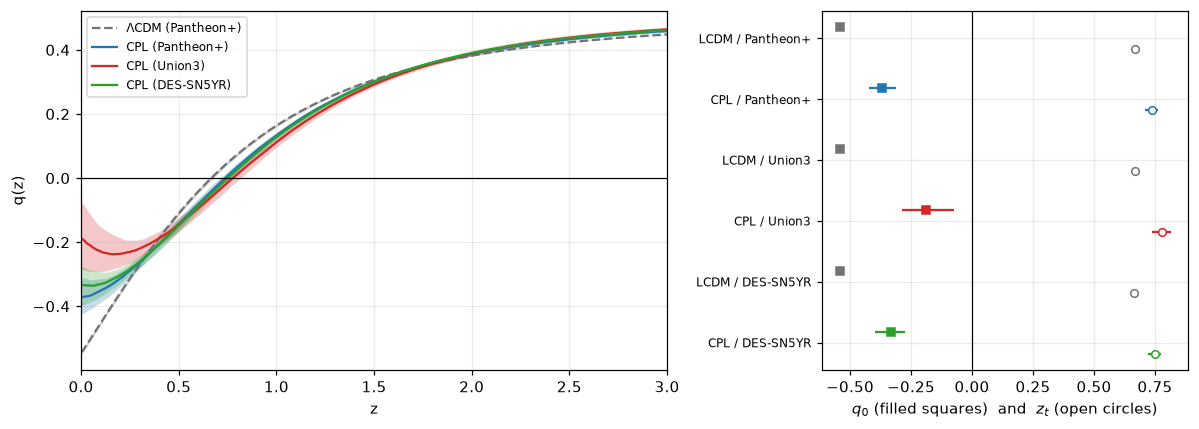

In [13]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.6, 1]})
lo, mid, hi = np.percentile(EXP["LCDM", "Pantheon+"]["q"], [16, 50, 84], axis=0)
a1.fill_between(Z, lo, hi, color=COLOR["LCDM"], alpha=0.35, lw=0)
a1.plot(Z, mid, "--", color=COLOR["LCDM"], label="ΛCDM (Pantheon+)")
for s_ in SN_SETS:
    lo, mid, hi = np.percentile(EXP["CPL", s_]["q"], [16, 50, 84], axis=0)
    a1.fill_between(Z, lo, hi, color=COLOR[s_], alpha=0.25, lw=0)
    a1.plot(Z, mid, color=COLOR[s_], label=f"CPL ({s_})")
a1.axhline(0, color="k", lw=0.8)
a1.set(xlabel="z", ylabel="q(z)", xlim=(0, 3))
a1.legend(fontsize=8)

for i, (m, s_) in enumerate(RUNS):
    color = COLOR["LCDM" if m == "LCDM" else s_]
    for key, y, marker, face in (("q0", i - 0.18, "s", color), ("z_t", i + 0.18, "o", "white")):
        lo, mid, hi = np.nanpercentile(EXP[m, s_][key], [16, 50, 84])
        a2.errorbar(mid, y, xerr=[[mid - lo], [hi - mid]], fmt=marker, color=color, mfc=face, ms=5)
a2.axvline(0, color="k", lw=0.8)
a2.set_yticks(range(len(RUNS)), [f"{m} / {s_}" for m, s_ in RUNS], fontsize=8)
a2.invert_yaxis()
a2.set_xlabel(r"$q_0$ (filled squares)  and  $z_t$ (open circles)")
fig.tight_layout()
savefig(fig, "deceleration")

for m, s_ in RUNS:
    e = EXP[m, s_]
    print(f"{m:4s} {s_:10s} q0 = {np.mean(e['q0']):.3f} ± {np.std(e['q0']):.3f}   "
          f"z_t = {np.nanmean(e['z_t']):.3f} ± {np.nanstd(e['z_t']):.3f}")

### $H(z)$ and the cosmic chronometers

The plot shows $H(z)/(1+z) = \dot a$, so acceleration appears as this curve rising towards today. The lower panel is the ratio to the ΛCDM best fit.

saved hubble_chronometers.svg (0.20 MB)


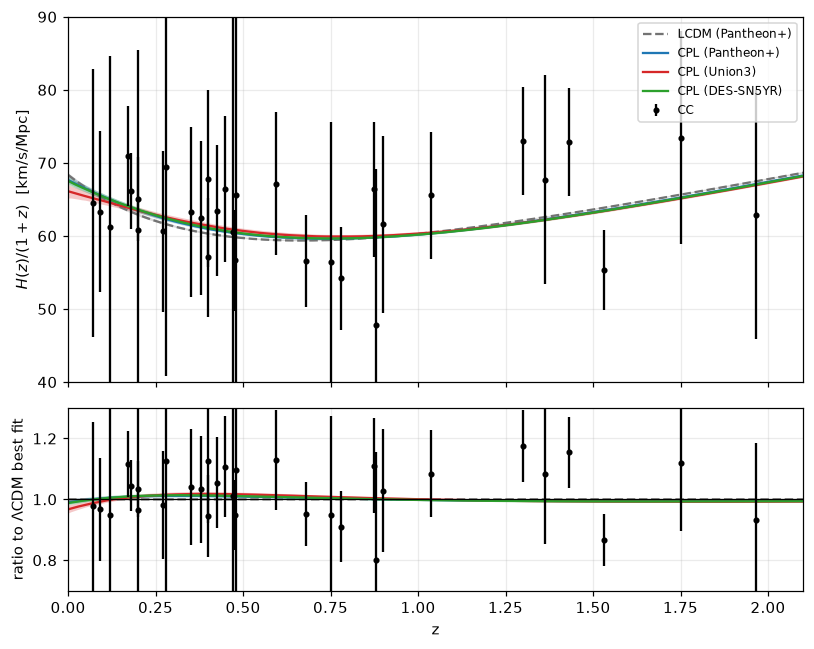

In [14]:
data_cc = cc.load_cc("favale2023")
sigma_cc = data_cc.covariance.sigma

ref = BEST_EXP["LCDM", "Pantheon+"]["H"]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(7.5, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for run_, color, ls in [(("LCDM", "Pantheon+"), COLOR["LCDM"], "--")] + [(("CPL", s_), COLOR[s_], "-") for s_ in SN_SETS]:
    H = EXP[run_]["H"]
    lo, mid, hi = np.percentile(H / (1 + Z), [16, 50, 84], axis=0)
    a1.fill_between(Z, lo, hi, color=color, alpha=0.25, lw=0)
    a1.plot(Z, mid, ls, color=color, label=f"{run_[0]} ({run_[1]})")
    lo, mid, hi = np.percentile(H / ref, [16, 50, 84], axis=0)
    a2.fill_between(Z, lo, hi, color=color, alpha=0.25, lw=0)
    a2.plot(Z, mid, ls, color=color)
interp = np.interp(data_cc.z, Z, ref)
a1.errorbar(data_cc.z, data_cc.H / (1 + data_cc.z), sigma_cc / (1 + data_cc.z), fmt="o", color="k", ms=3, label="CC")
a2.errorbar(data_cc.z, data_cc.H / interp, sigma_cc / interp, fmt="o", color="k", ms=3)
a1.set(ylabel=r"$H(z)/(1+z)$  [km/s/Mpc]", ylim=(40, 90))
a2.set(xlabel="z", ylabel="ratio to ΛCDM best fit", ylim=(0.7, 1.3), xlim=(0, 2.1))
a2.axhline(1, color="k", lw=0.8)
a1.legend(fontsize=8)
fig.tight_layout()
savefig(fig, "hubble_chronometers")

### DESI DR2 BAO distances

The three observables, as ratios to the ΛCDM (Pantheon+) best fit: $D_M/r_d$ (transverse), $D_H/r_d = c/(H r_d)$ (line of sight), and $D_V/r_d$ (angle-averaged, BGS only). CPL departs most in $D_H$ at $z \lesssim 1$, where dark energy dominates.

saved bao_distances.svg (0.19 MB)


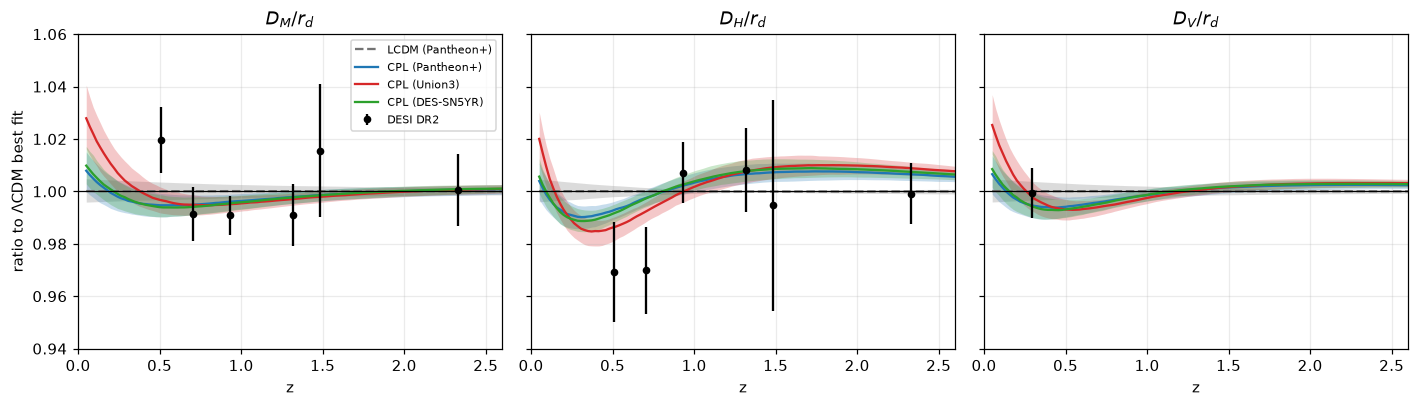

In [15]:
data_bao = bao.load_desi("desi2025")
sigma_bao = data_bao.covariance.sigma
ref = BEST_EXP["LCDM", "Pantheon+"]
names = {"DM_over_rs": ("DM", r"$D_M/r_d$"), "DH_over_rs": ("DH", r"$D_H/r_d$"), "DV_over_rs": ("DV", r"$D_V/r_d$")}

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (obs, (key, label)) in zip(axes, names.items()):
    for run_, color, ls in [(("LCDM", "Pantheon+"), COLOR["LCDM"], "--")] + [(("CPL", s_), COLOR[s_], "-") for s_ in SN_SETS]:
        lo, mid, hi = np.percentile(EXP[run_][key] / ref[key], [16, 50, 84], axis=0)
        ax.fill_between(Z_BAO, lo, hi, color=color, alpha=0.25, lw=0)
        ax.plot(Z_BAO, mid, ls, color=color, label=f"{run_[0]} ({run_[1]})")
    sel = np.array([o == obs for o in data_bao.observable])
    model_at = np.interp(data_bao.z[sel], Z_BAO, ref[key])
    ax.errorbar(data_bao.z[sel], data_bao.value[sel] / model_at, sigma_bao[sel] / model_at,
                fmt="o", color="k", ms=4, label="DESI DR2")
    ax.axhline(1, color="k", lw=0.8)
    ax.set(xlabel="z", title=label, ylim=(0.94, 1.06), xlim=(0, 2.6))
axes[0].set_ylabel("ratio to ΛCDM best fit")
axes[0].legend(fontsize=7.5)
fig.tight_layout()
savefig(fig, "bao_distances")

### SN Ia Hubble-diagram residuals

For each SN set, the residual is $\Delta\mu = \mu_\mathrm{data} - \mu_\mathrm{ΛCDM}$ against the ΛCDM best fit to the same set. The supernovae's absolute magnitude (or offset) is free, so only the **shape** means anything: the offset is fit with the full covariance and removed. The curve is the CPL best fit minus the ΛCDM one, with its offset removed the same way.

Pantheon+ and DES-SN5YR are binned in $\log z$ for display. The bin errors use only the diagonal errors and ignore correlations, so they understate the uncertainty. Union3 comes binned already.

saved sn_residuals.svg (0.61 MB)


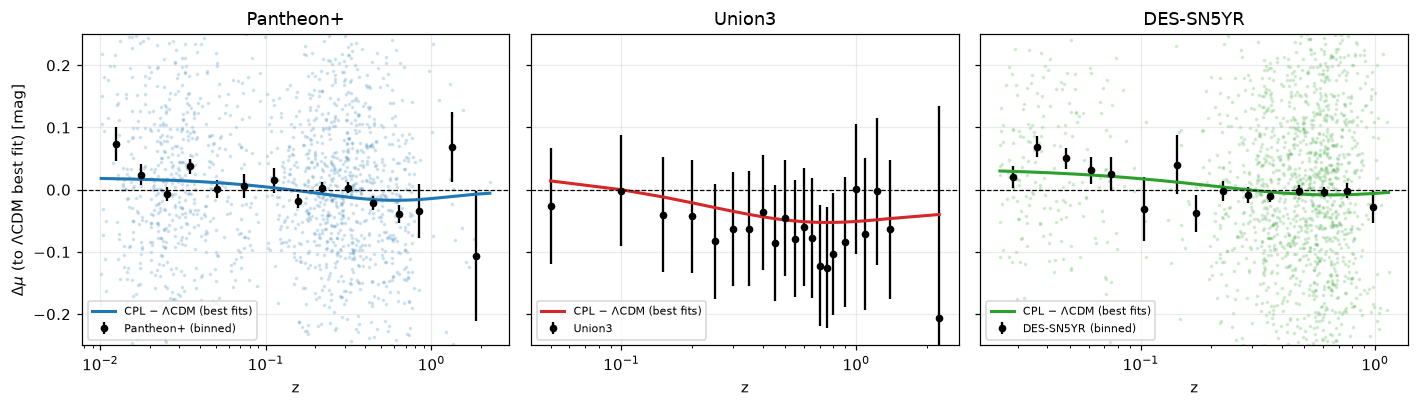

In [16]:
def sn_data(name):
    if name == "Pantheon+":
        d = sn.load_pantheon()
        return d.z_hd, d.z_hel, d.m_b_corr, d.covariance
    if name == "Union3":
        d = sn.load_union3()
        return d.z_cmb, d.z_hel, d.mu, d.covariance
    d = sn.load_des_sn5yr()
    return d.z_hd, d.z_hel, d.mu, d.covariance

def remove_offset(r, cov):
    ones = np.ones_like(r)
    return r - (ones @ cov.solve(r)) / (ones @ cov.solve(ones))

def model_mu(run_, z, z_hel):
    m, bg = BG[run_[0]]
    m.logposterior({n: BEST[run_]["point"][n] for n in m.parameters.sampled})
    return 5 * np.log10((1 + z_hel) * bg.get_DM(z)) + 25

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, s_ in zip(axes, SN_SETS):
    z, z_hel, mu, cov = sn_data(s_)
    mu_lcdm = model_mu(("LCDM", s_), z, z_hel)
    mu_cpl = model_mu(("CPL", s_), z, z_hel)
    resid = remove_offset(mu - mu_lcdm, cov)
    diff = remove_offset(mu_cpl - mu_lcdm, cov)
    sigma = cov.sigma
    if len(z) > 100:
        edges = np.geomspace(z.min(), z.max() * 1.001, 16)
        idx = np.digitize(z, edges) - 1
        zb, rb, eb = [], [], []
        for k in range(len(edges) - 1):
            sel = idx == k
            if sel.sum() < 3:
                continue
            w = 1 / sigma[sel] ** 2
            zb.append(np.exp(np.average(np.log(z[sel]), weights=w)))
            rb.append(np.average(resid[sel], weights=w))
            eb.append(w.sum() ** -0.5)
        ax.scatter(z, resid, s=2, color=COLOR[s_], alpha=0.15)
        ax.errorbar(zb, rb, eb, fmt="o", color="k", ms=4, label=f"{s_} (binned)")
    else:
        ax.errorbar(z, resid, sigma, fmt="o", color="k", ms=4, label=s_)
    order = np.argsort(z)
    ax.plot(z[order], diff[order], color=COLOR[s_], lw=2, label="CPL − ΛCDM (best fits)")
    ax.axhline(0, color="k", lw=0.8, ls="--")
    ax.set(xscale="log", xlabel="z", title=s_, ylim=(-0.25, 0.25))
    ax.legend(fontsize=7.5, loc="lower left")
axes[0].set_ylabel(r"$\Delta\mu$ (to ΛCDM best fit) [mag]")
fig.tight_layout()
savefig(fig, "sn_residuals")

## 7. $H_0$, $\Omega_m$, $S_8$, $r_d$ across the six runs

The grey band is Planck 2018 (TT,TE,EE+lowE+lensing, ΛCDM): $H_0 = 67.36 \pm 0.54$, $\Omega_m = 0.3153 \pm 0.0073$, $S_8 = 0.832 \pm 0.013$, $r_d = 147.09 \pm 0.26$ Mpc. The orange band is SH0ES (Riess et al. 2022): $H_0 = 73.04 \pm 1.04$.

CPL does not ease the $H_0$ tension; it pulls $H_0$ down. The $w_0 > -1$ that DESI prefers slows today's expansion, and $H_0$ drops to keep the distance to last scattering, $D_M(z_*)$, where the CMB fixes it.

saved parameters_across_runs.svg (0.08 MB)


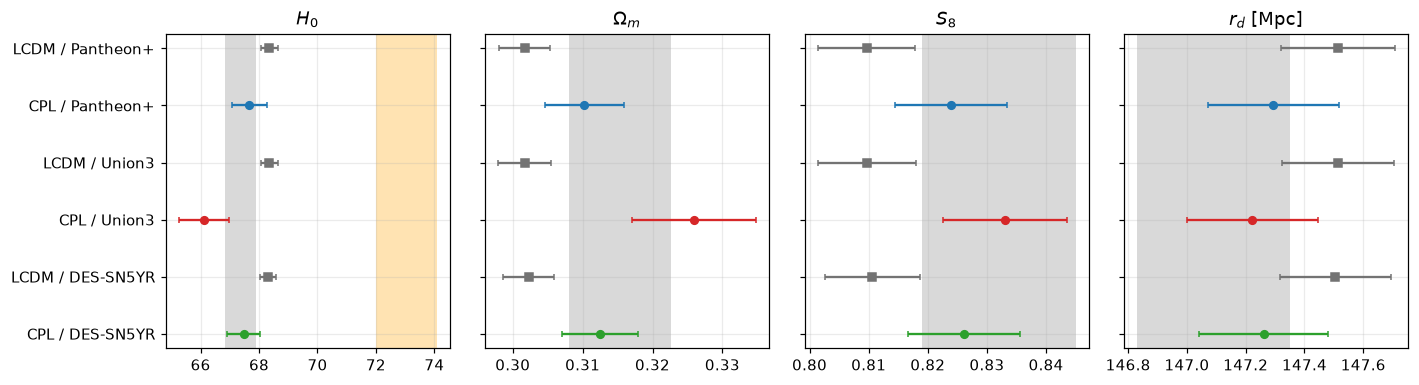

In [17]:
params = [("H0", r"$H_0$", (67.36, 0.54), (73.04, 1.04)),
          ("Omega_m", r"$\Omega_m$", (0.3153, 0.0073), None),
          ("S8", r"$S_8$", (0.832, 0.013), None),
          ("rdrag", r"$r_d$ [Mpc]", (147.09, 0.26), None)]

fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), sharey=True)
for ax, (p, label, planck, shoes) in zip(axes, params):
    ax.axvspan(planck[0] - planck[1], planck[0] + planck[1], color="0.85", lw=0)
    if shoes:
        ax.axvspan(shoes[0] - shoes[1], shoes[0] + shoes[1], color="orange", alpha=0.3, lw=0)
    for i, (m, s_) in enumerate(RUNS):
        s = samples[m, s_]
        ax.errorbar(s.mean(p), i, xerr=s.std(p), fmt="s" if m == "LCDM" else "o", ms=5, capsize=2,
                    color=COLOR["LCDM"] if m == "LCDM" else COLOR[s_])
    ax.set(title=label)
axes[0].set_yticks(range(len(RUNS)), [f"{m} / {s_}" for m, s_ in RUNS])
axes[0].invert_yaxis()
fig.tight_layout()
savefig(fig, "parameters_across_runs")

## 8. Model comparison

$k$ is the number of free parameters (ΛCDM: 6 + `A_planck` = 7, CPL: 9) and $N$ the number of data points.

- **Likelihood-ratio test.** $\Delta\chi^2 = \chi^2_\mathrm{min,ΛCDM} - \chi^2_\mathrm{min,CPL}$. ΛCDM is nested in CPL, so $\Delta\chi^2 \ge 0$, and by Wilks' theorem it follows a $\chi^2$ distribution with $\Delta k = 2$ degrees of freedom. That gives a p-value and its two-sided Gaussian equivalent, "σ".
- **AIC** $= \chi^2_\mathrm{min} + 2k$, so $\Delta\mathrm{AIC} = \mathrm{AIC}_\mathrm{ΛCDM} - \mathrm{AIC}_\mathrm{CPL} = \Delta\chi^2 - 4$. On Burnham & Anderson's scale, $|\Delta| < 2$ is no difference, 4–7 is considerably less support for the weaker model, and $> 10$ essentially rules it out.
- **BIC** $= \chi^2_\mathrm{min} + k \ln N$. The penalty grows with $N$: $\Delta\mathrm{BIC} = \Delta\chi^2 - 2\ln N \approx \Delta\chi^2 - 15$. On Kass & Raftery's scale, 2–6 is positive, 6–10 strong and $>10$ very strong evidence. Note that $N$ depends on whether the supernovae are binned: Union3 gives 22 bins, the other two give ~1600–1800 individual SNe. Comparing BIC across SN sets can therefore mislead.

None of these accounts for the prior volume. That needs the Bayesian evidence (the `nested` sampler).

$\chi^2_\mathrm{min}$ comes from a Nelder–Mead minimization (`bestfit.py`) started at the chain's best point. The chain's own lowest χ² is listed alongside: in 7–9 dimensions a chain typically misses the minimum by ~0.2–0.5.

In [18]:
def k_of(model):
    return len(BG[model][0].parameters.sampled) + 4      # + tau, lnAs, n_s, A_planck

rows, comparisons = {}, {}
for s_ in SN_SETS:
    n_data = sum(N_DATA[s_].values())
    c = model_comparison.compare_models(
        name_null="LCDM", chi2_null=BEST["LCDM", s_]["chi2"], k_null=k_of("LCDM"),
        name_alt="CPL", chi2_alt=BEST["CPL", s_]["chi2"], k_alt=k_of("CPL"), n_data=n_data)
    comparisons[s_] = c
    lrt = c["likelihood_ratio_test"]
    rows[s_] = {
        "N": n_data,
        "χ²_min ΛCDM": f"{c['LCDM']['chi2']:.2f}",
        "χ²_min CPL": f"{c['CPL']['chi2']:.2f}",
        "χ²_min in chain (ΛCDM / CPL)": f"{BEST['LCDM', s_]['chi2_chain']:.2f} / {BEST['CPL', s_]['chi2_chain']:.2f}",
        "Δχ²": f"{lrt['delta_chi2']:.2f}",
        "p (Δk = 2)": f"{lrt['p_value']:.2g}",
        "σ": f"{lrt['sigma']:.2f}",
        "ΔAIC": f"{c['delta_AIC']:+.2f}",
        "ΔBIC": f"{c['delta_BIC']:+.2f}",
    }
pd.DataFrame(rows)

,Pantheon+,Union3,DES-SN5YR
N,2287,719,2517
χ²_min ΛCDM,2426.99,1049.63,2656.36
χ²_min CPL,2417.78,1034.38,2643.95
χ²_min in chain (ΛCDM / CPL),2427.16 / 2418.03,1050.11 / 1034.72,2656.49 / 2644.27
Δχ²,9.21,15.25,12.41
p (Δk = 2),0.01,0.00049,0.002
σ,2.58,3.49,3.09
ΔAIC,+5.21,+11.25,+8.41
ΔBIC,-6.26,+2.10,-3.25


Left: the significance from the likelihood-ratio test. Right: ΔAIC and ΔBIC (positive favours CPL), with the thresholds of the scales above as dotted lines.

saved model_comparison.svg (0.05 MB)


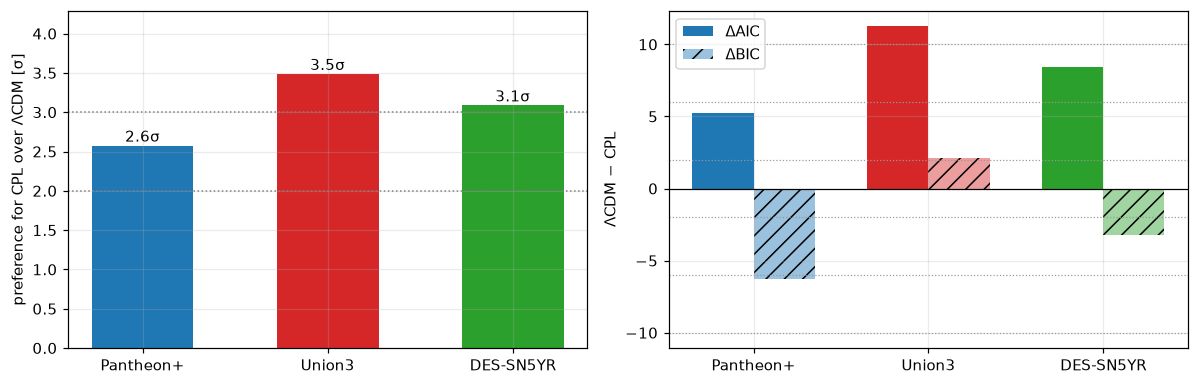

In [19]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
x = np.arange(len(SN_SETS))
sig = [comparisons[s_]["likelihood_ratio_test"]["sigma"] for s_ in SN_SETS]
a1.bar(x, sig, color=[COLOR[s_] for s_ in SN_SETS], width=0.55)
for xi, v in zip(x, sig):
    a1.text(xi, v + 0.05, f"{v:.1f}σ", ha="center")
for level in (2, 3):
    a1.axhline(level, color="0.5", ls=":", lw=1)
a1.set_xticks(x, list(SN_SETS))
a1.set(ylabel="preference for CPL over ΛCDM [σ]", ylim=(0, max(sig) + 0.8))

width = 0.35
aic = [comparisons[s_]["delta_AIC"] for s_ in SN_SETS]
bic = [comparisons[s_]["delta_BIC"] for s_ in SN_SETS]
a2.bar(x - width / 2, aic, width, color=[COLOR[s_] for s_ in SN_SETS], label="ΔAIC")
a2.bar(x + width / 2, bic, width, color=[COLOR[s_] for s_ in SN_SETS], alpha=0.45, hatch="//", label="ΔBIC")
for level in (-10, -6, -2, 0, 2, 6, 10):
    a2.axhline(level, color="k" if level == 0 else "0.6", ls="-" if level == 0 else ":", lw=0.8)
a2.set_xticks(x, list(SN_SETS))
a2.set(ylabel="ΛCDM − CPL")
a2.legend()
fig.tight_layout()
savefig(fig, "model_comparison")

### Which data say what?

The contribution of each likelihood to $\Delta\chi^2 = \chi^2_\mathrm{ΛCDM} - \chi^2_\mathrm{CPL}$ at the best-fit points. Positive means that data are fit better at CPL's best point. The contributions add up to the Δχ² above. Since the two best points differ, individual contributions can offset each other: the CMB, for example, can give a little to let CPL fit the late-time data.

saved chi2_by_likelihood.svg (0.04 MB)


,Pantheon+,Union3,DES-SN5YR
Planck TT/TE/EE,3.01,2.72,2.62
Planck lowE,0.60,1.57,0.69
Planck lensing,0.25,0.09,0.16
DESI DR2,2.53,3.90,3.37
SN,2.68,6.95,5.43
CC,0.14,0.02,0.13


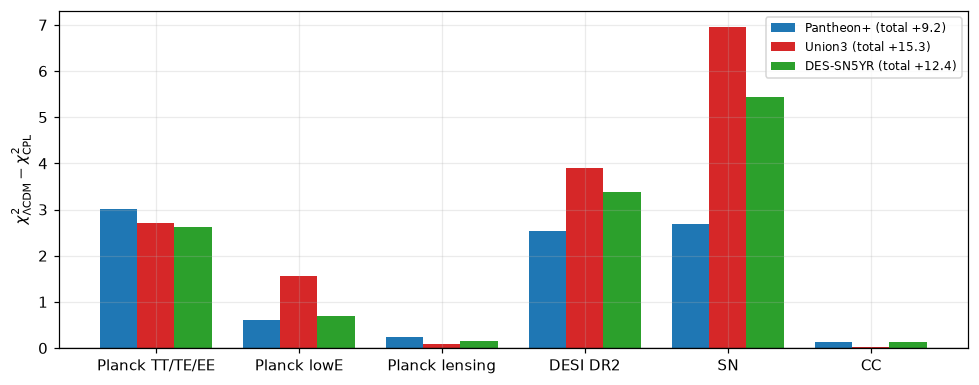

In [20]:
short = {"cmb.planck_lite": "Planck TT/TE/EE", "cmb.planck_lowe": "Planck lowE", "cmb.planck_lensing": "Planck lensing",
         "bao.desi": "DESI DR2", "sn.pantheonplus": "SN", "sn.union3": "SN", "sn.des_sn5yr": "SN",
         "cc.chronometers": "CC"}
groups = ["Planck TT/TE/EE", "Planck lowE", "Planck lensing", "DESI DR2", "SN", "CC"]

delta = {}
for s_ in SN_SETS:
    a, b = BEST["LCDM", s_]["parts"], BEST["CPL", s_]["parts"]
    delta[s_] = {g: 0.0 for g in groups}
    for k in a:
        delta[s_][short[k]] += a[k] - b[k]

fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(groups))
width = 0.26
for j, s_ in enumerate(SN_SETS):
    ax.bar(x + (j - 1) * width, [delta[s_][g] for g in groups], width, color=COLOR[s_],
           label=f"{s_} (total {sum(delta[s_].values()):+.1f})")
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(x, groups)
ax.set_ylabel(r"$\chi^2_\mathrm{ΛCDM} - \chi^2_\mathrm{CPL}$")
ax.legend(fontsize=8)
fig.tight_layout()
savefig(fig, "chi2_by_likelihood")
pd.DataFrame(delta).round(2)

## 9. How accurate the emulator is

At each point the emulator gives its prediction together with the predicted $\ln L$ error of that prediction, and uses the prediction only where the error is below 0.05. This section is an independent check. Random points are drawn from the Pantheon+ posteriors, and the total $\ln L$ is recomputed with the same input using the `camb` theory, without the emulator.

CAMB takes ~1–2 s per point, so the check takes a few minutes. Set `CHECK = False` to skip it.

LCDM: |Δln L| median 0.0023, max 0.0093, mean Δln L -0.0002
CPL: |Δln L| median 0.0022, max 0.0152, mean Δln L -0.0014
saved emulator_accuracy.svg (0.03 MB)


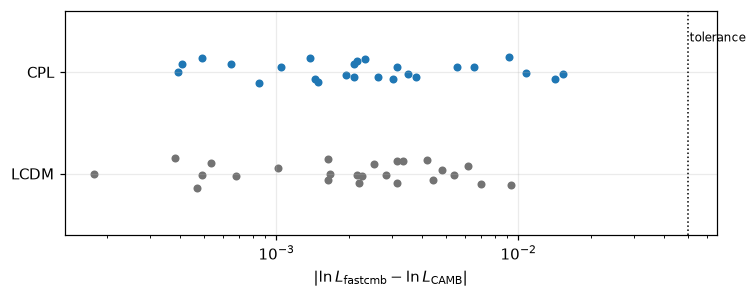

In [21]:
CHECK, N_CHECK = True, 25

def check_emulator(model, sn_set="Pantheon+"):
    info = load_info(str(config(model, sn_set)))
    info.pop("sampler"); info.pop("output")
    fast = get_model(info)                                  # with the run's learned points
    info = load_info(str(config(model, sn_set)))
    info.pop("sampler"); info.pop("output")
    info["theory"].pop("fastcmb")
    info["theory"]["camb"] = None
    slow = get_model(info)
    d = draws(samples[model, sn_set], fast.parameters.sampled, N_CHECK)
    diff = []
    for i in range(N_CHECK):
        p = {k: v[i] for k, v in d.items()}
        a, b = fast.logposterior(p), slow.logposterior(p)
        diff.append(sum(a.loglikes.values()) - sum(b.loglikes.values()))
    return np.array(diff)

if CHECK:
    ERR = {model: check_emulator(model) for model in MODELS}
    fig, ax = plt.subplots(figsize=(7, 2.8))
    for j, model in enumerate(MODELS):
        e = ERR[model]
        ax.scatter(np.abs(e), np.full(len(e), j) + rng.uniform(-0.15, 0.15, len(e)),
                   color=COLOR["LCDM" if model == "LCDM" else "Pantheon+"], s=18)
        print(f"{model}: |Δln L| median {np.median(np.abs(e)):.4f}, max {np.abs(e).max():.4f}, "
              f"mean Δln L {e.mean():+.4f}")
    ax.axvline(0.05, color="k", ls=":", lw=1)
    ax.text(0.051, 1.3, "tolerance", fontsize=8)
    ax.set_yticks(range(len(MODELS)), MODELS)
    ax.set(xscale="log", xlabel=r"$|\ln L_\mathrm{fastcmb} - \ln L_\mathrm{CAMB}|$", ylim=(-0.6, 1.6))
    fig.tight_layout()
    savefig(fig, "emulator_accuracy")

Where the emulator ran CAMB. A model's three SN runs share one training set, and in the $(w_0, w_a)$ plane its points gather around the posteriors. The scattered points far out are where chains passed through at the start, or where rejected proposals landed. The cluster at the lower right ($w_a \approx -2 \ldots -3$) is left from a first attempt at the DES-SN5YR CPL run, in which one chain started far from the posterior and stayed there. That run was restarted from a narrower starting distribution (`cpl_des_sn5yr.yaml`).

LCDM: 272 CAMB points (all three SN runs), inputs ['N_eff', 'Omega_k', 'h', 'ln1e10As', 'm_nu', 'n_s', 'omega_b', 'omega_cb', 'tau_reio']
CPL: 642 CAMB points (all three SN runs), inputs ['D_M_star', 'N_eff', 'Omega_k', 'h', 'ln1e10As', 'm_nu', 'n_s', 'omega_b', 'omega_cb', 'tau_reio', 'w0', 'wa']


saved training_points.svg (0.35 MB)


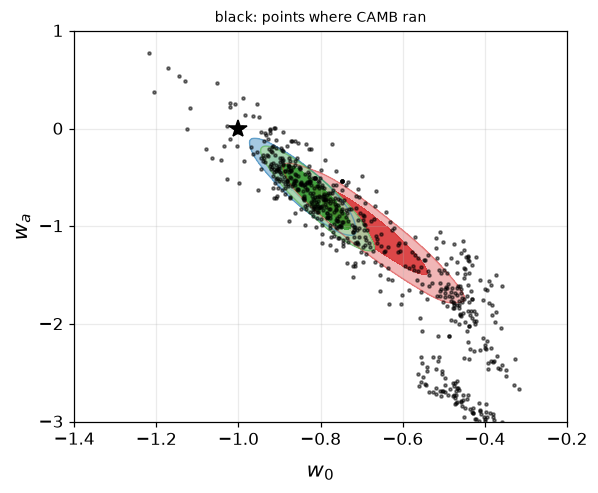

In [22]:
def training_points(model):
    out = []
    for f in glob.glob(str(ROOT / "chains" / "cpl_vs_lcdm" / f"emu_{model.lower()}" / "*.npz")):
        with np.load(f) as d:
            if len(d["X"]):
                out.append(([str(n) for n in d["names"]], d["X"]))
    return out[0][0], np.concatenate([x for _, x in out])

for model in MODELS:
    names, X = training_points(model)
    print(f"{model}: {len(X)} CAMB points (all three SN runs), inputs {names}")

names, X = training_points("CPL")
g = plots.get_single_plotter(width_inch=5.5, ratio=0.8)
g.plot_2d(cpl, "w0", "wa", filled=True, colors=[COLOR[s_] for s_ in SN_SETS])
ax = g.subplots[0, 0]
ax.scatter(X[:, names.index("w0")], X[:, names.index("wa")], s=4, color="k", alpha=0.5, zorder=5)
ax.plot(-1, 0, "k*", ms=12, zorder=10)
ax.set(xlim=(-1.4, -0.2), ylim=(-3, 1))
ax.set_title("black: points where CAMB ran", fontsize=9)
savefig(g.fig, "training_points")

## 10. Conclusions

| | Pantheon+ | Union3 | DES-SN5YR (Dovekie) |
|---|---|---|---|
| $w_0$ | $-0.843 \pm 0.054$ | $-0.677 \pm 0.090$ | $-0.809 \pm 0.056$ |
| $w_a$ | $-0.59 \pm 0.20$ | $-1.04^{+0.32}_{-0.28}$ | $-0.70 \pm 0.22$ |
| Δχ² → σ (Δk = 2) | 9.2 → 2.6σ | 15.3 → 3.5σ | 12.4 → 3.1σ |
| ΔAIC / ΔBIC | +5.2 / −6.3 | +11.3 / +2.1 | +8.4 / −3.3 |
| DESI DR2 paper (DESI+CMB+SN) | 2.8σ | 3.8σ | 4.2σ (pre-Dovekie DESY5) |

- **All three SN sets point the same way.** The posteriors sit in the quintom-b region: $w > -1$ today and $w < -1$ at $z \gtrsim 0.4$. The distance from ΛCDM is 2.6σ with Pantheon+ and 3.5σ with Union3. The Pantheon+ and Union3 results match the DESI DR2 paper to within 0.1σ in $w_0, w_a$. A slightly lower significance than the paper's is expected: the CMB here is plik_lite with Planck lensing only, while the paper adds CamSpec and ACT lensing.
- **The DES-SN5YR difference comes from the data release.** The Dovekie recalibration that CosmoFit loads weakens the signal of the original release: 3.1σ here against 4.2σ for the paper's DESY5.
- **The verdict depends on the criterion.** AIC prefers CPL in all three cases, strongly with Union3 (+11) and weakly with Pantheon+ (+5). BIC prefers ΛCDM with Pantheon+ and with DES, because the $k\ln N$ penalty grows to ≈15 with ~2500 individual SNe. Union3 passing BIC is partly just its 22 bins: a consequence of how the data are counted, not evidence.
- **No single dataset carries the signal.** At the best-fit points Δχ² is shared between DESI BAO (+2.5…+3.9), the SNe (+2.7…+7.0) and Planck TT/TE/EE (+2.6…+3.0). The chronometers carry no information on this question (+0.1).
- **Physical consequences:**
  - The dark energy density peaks at $z \approx 0.4$–0.5 and falls 5–20% towards today.
  - Today's acceleration is weaker than in ΛCDM: $q_0 \approx -0.2 \ldots -0.37$ against $-0.54$. Acceleration began earlier: $z_t \approx 0.74$–0.78 against 0.67.
  - $H_0$ falls (66.1–67.7) and the Hubble tension grows; $\Omega_m$ and $S_8$ rise.
- **The emulator.** Against CAMB, $|\Delta \ln L|$ is at most 0.015 (tolerance 0.05), negligible beside the Δχ² of the model comparison (≥ 9). The six runs needed 272 (ΛCDM) and 642 (CPL) CAMB calls in total.

**Limits.** CPL is a parametrization: the phantom behaviour at high $z$ comes largely from the form it imposes. Δχ², AIC and BIC do not see the prior volume. A firmer model comparison needs the Bayesian evidence, or a reconstruction of $w(z)$ that does not depend on the parametrization (binned or Gaussian-process).